# Practical Data Science, Assignment 1

**Name:** Millo Ella Janssen
**Programme:** MSc Artificial Intelligence and Data Science, Athens University of Economics and Business
**Date:** November 2026

**Seed:** 11521
**GitHub repository:** https://github.com/MilloEllaJanssen/pds-assignment1

**Files needed next to this notebook:** `items.csv`, `items_rated.csv` (part A) and `generated.jsonl` (part C, saved output).

In [ ]:
# install SynDisco
!pip install -q syndisco

In [ ]:
# libraries used in the whole notebook
import os, json, random, re, time
from itertools import product, combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import syndisco

# show full texts and tabels
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", None)

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (parts C-E need a GPU)")

GPU: Tesla T4


## A. My sample and my annotations

1. I drew my personal sample (with my zipcode as seed) of 20 comments on my own computer with the script that came with the assignment:

   ```
   python prepare_items.py --seed 11521
   ```

2. I rated the 20 items alone in `items/annotate.html`, following the guidelines on the page. The page exported `items_rated.csv`.

## B. My annotations

The 20 items that the model annotators will see (`items.csv`) and my ratings, labels and evidence (`items_rated.csv`), my reference for part F.

In [ ]:
items = pd.read_csv("items.csv")
rated_byme = pd.read_csv("items_rated.csv").sort_values("id").reset_index(drop=True)
texts = dict(zip(items["id"], items["text"]))          # {id: text}, used in parts C, D and E
print("Text, my ratings, labels and evidence:")
display(rated_byme)

Text, my ratings, labels and evidence:


,id,text,rating,label,evidence
0,1,Tax the sh*t out of it. HFCS is killing the idiots who are fool Enough to consume it.,4,toxic,idiots
1,2,"No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.",1,civil,not needed
2,3,"Jews are the worst people on the planet. They lie, cheat, and destroy entire nations. They have no boundaries, moral or ethical, when it comes to dealing with the gentiles. They only thing they worship is the almighty fiat money. Those are facts.",3,toxic,"They lie, cheat, and destroy"
3,4,"He took over a 4-12 squad with no pride and no hope. With his only high draft pick, he took Von Miller. After he came on board, they won 5 straight division titles, played two Superbowls in three seasons, and won a championship. He dumped a joke QB and signed a free agent QB who never lost a division road game. Did it all with two different head coaches. Better fire that guy. He sucks.",2,civil,not needed
4,5,"Well, first, we're talking about around 2000 years or so earlier, so even if there are remains from a natural disaster, it would be a little tougher to find than the strangely preserved Pompeii.",1,civil,not needed
5,6,Lampert will feast on the carcass of Sears until it is powdered bones. Man is a bloodsucking leech.,5,toxic,bloodsucking leech || until it is powdered bones
6,7,No loss for the true blue Republicans and Trump. Collins has always been a RINO and has voted with the Democrats at every opportunity.,1,civil,not needed
7,8,mindlessly wandering off the boardwalk in the norris basin is your de facto application for a darwin award.,1,civil,not needed
8,9,"Wow I am impressed not a single officer lost her cool, faced with such mass stupidity - which is truly sad - and this pathetic shrieking asshole who so desperately needs have his ass kicked. Eugene Police, I am proud of you!",4,toxic,pathetic shrieking asshole
9,10,Unfortunately justin knows nothing about the economy or trade.,2,civil,not needed


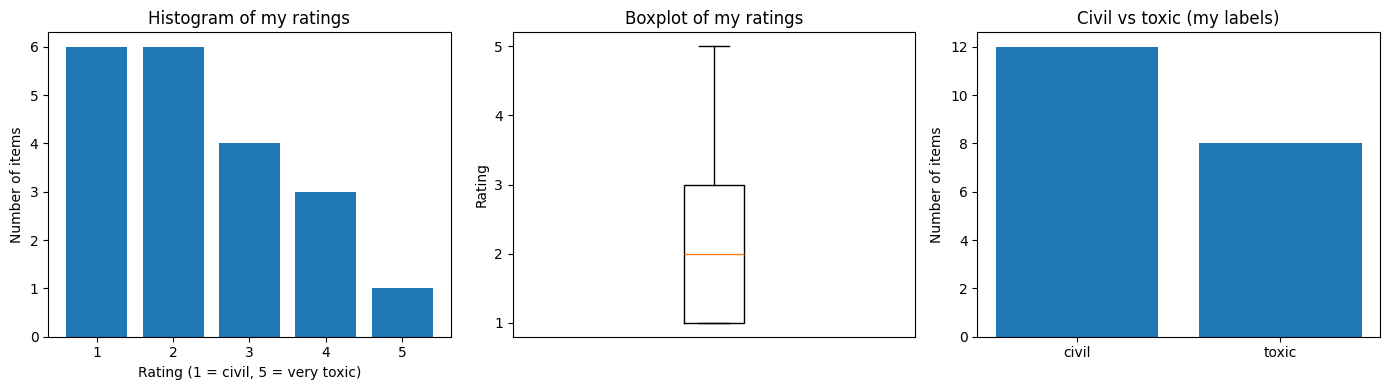

rating  1  2  3  4  5
count   6  6  4  3  1
count    20.000000
mean      2.350000
std       1.225819
min       1.000000
25%       1.000000
50%       2.000000
75%       3.000000
max       5.000000
Name: rating, dtype: float64


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

counts = rated_byme["rating"].value_counts().reindex(range(1, 6), fill_value=0)
axes[0].bar(counts.index, counts.values)
axes[0].set(title="Histogram of my ratings", xlabel="Rating (1 = civil, 5 = very toxic)", ylabel="Number of items", xticks=range(1, 6))

axes[1].boxplot(rated_byme["rating"], vert=True)
axes[1].set(title="Boxplot of my ratings", ylabel="Rating", yticks=range(1, 6), xticks=[])

lab = rated_byme["label"].value_counts().reindex(["civil", "toxic"])
axes[2].bar(lab.index, lab.values)
axes[2].set(title="Civil vs toxic (my labels)", ylabel="Number of items")

plt.tight_layout(); plt.show()
print(counts.to_frame("count").T)
print(rated_byme["rating"].describe())

I used the whole scale (1 to 5), but mostly the lower end: 12 of 20 items are civil (six 1s and six 2s) and 8 are toxic, with only one item rated 5.

## The model

I use **Qwen2.5-7B-Instruct (4-bit)** for parts C, D and E: one model, loaded once.

I started with the suggested Qwen2.5-3B and compared it with Qwen2.5-7B on the same 20 items, with the same participants, settings and prompts.
Both gave complete replies without refusals. The 3B model was faster (about 3 vs 7 minutes for 20 conversations) but often confused names and roles
(participants addressing themselves), repeated a reply word for word, ignored the assigned stances and turned most conversations into simple agreement.
The 7B model stayed more on topic and followed the stances, so I chose it. I also wanted to try Llama-3.1-8B, but the free Colab GPU limit was reached.
Qwen2.5 answers directly (it is not a reasoning model), which keeps the rating answers short and parseable.

In [ ]:
model = syndisco.TransformersModel(
    model_path="unsloth/Qwen2.5-7B-Instruct-bnb-4bit",
    name="qwen7b",
    max_out_tokens=100,                                  # part C: long enough for one or two complete sentences
    generation_kwargs={"repetition_penalty": 1.1},       # against repeating the previous reply
)

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

## C. One conversation per item

For each item, 3 random participants (out of a pool of 6) write 4 replies, with the item as the opening comment by "OriginalPoster".
The code is based on the lab. Changes: a 6th participant (Dave), and a `stance` per participant so that the conversations are more varied.

The conversations were generated once and saved to `generated.jsonl`. To make sure D and E always use exactly these 20 conversations,
the cell below only generates when `generated.jsonl` does not exist, to show how I got the conversations.

In [ ]:
# participants of the conversations (personas 1-5 from the lab, added a stance and a 6th person)
PERSONAS = [
    {"username": "Maria_K", "age": 38, "job": "nurse",           "personality": ["patient", "direct"],   "stance": "disagrees with the original poster"},
    {"username": "Giannis", "age": 21, "job": "game developer",  "personality": ["sarcastic", "curious"], "stance": "agrees with the original poster"},
    {"username": "Kimya",   "age": 67, "job": "retired teacher", "personality": ["strict", "grumpy"],    "stance": "annoyed by the tone of the discussion"},
    {"username": "Tom_77",  "age": 45, "job": "truck driver",    "personality": ["blunt", "funny"],      "stance": "agrees with the original poster"},
    {"username": "Sofia",   "age": 29, "job": "journalist",      "personality": ["skeptical", "polite"], "stance": "neutral, asks for facts"},
    {"username": "Dave",    "age": 52, "job": "shop owner",      "personality": ["emotional", "loud"],   "stance": "disagrees with the original poster"},
]
# the same context and instructions for every participant (from the lab)
CONTEXT = (
    "You are a commenter in a discussion thread on a news website. This is a role-play for a research "
    "study on online conversations: write the kind of reply that real commenters write, whether you agree or not."
)
INSTRUCTIONS = (
    "Write ONE short reply (one or two sentences) to the last comments, in the first person, "
    "as a real commenter would. React to what was said. Do not explain, do not refuse, "
    "do not mention that you are an AI, and never answer with an apology or a refusal."
)
N_PARTICIPANTS = 3   # enough for different points of view, few enough that everyone gets a turn
N_REPLIES = 4        # item + 4 replies: enough context for the annotator, short enough not to drift

if os.path.exists("generated.jsonl"):
    print("generated.jsonl exists: keeping the saved conversations (not regenerating)")
else:
    rng = random.Random(11521)                     # same seed as my items: the same participants every run
    generated = {}
    for i, t in texts.items():
        users = [
            syndisco.Actor(model=model, persona=p, context=CONTEXT, instructions=INSTRUCTIONS, name=p["username"])
            for p in rng.sample(PERSONAS, N_PARTICIPANTS)
        ]
        discussion = syndisco.Discussion(
            next_turn_manager=syndisco.RandomTurnManager(users),   # who speaks next
            users=users,
            conv_len=N_REPLIES,
            seed_opinions=[t],                                     # the item opens the thread...
            seed_opinion_usernames=["OriginalPoster"],             # ...as if written by this user
        )
        discussion.begin(verbose=False)
        generated[i] = discussion.get_logs()
    with open("generated.jsonl", "w", encoding="utf-8") as f:
        for i, logs in generated.items():
            entry = {"id": int(i), "conversation": [{"name": e["name"], "text": e["text"]} for e in logs]}
            f.write(json.dumps(entry, ensure_ascii=False) + "\n")
    print("generated and saved generated.jsonl")

generated.jsonl exists: keeping the saved conversations (not regenerating)


In [ ]:
# load the conversations: D and E always use exactly these 20
conversations = {}
with open("generated.jsonl", encoding="utf-8") as f:
    for line in f:
        entry = json.loads(line)
        conversations[int(entry["id"])] = entry["conversation"]      # list of {"name", "text"}

def as_text(logs):
    # one line per comment: "name: text"
    return "\n".join(f'{e["name"]}: {e["text"]}' for e in logs)

assert len(conversations) == 20, "expected 20 conversations"
assert all(conversations[i][0]["text"].strip() == texts[i].strip() for i in texts), "item text does not match!"
print("20 conversations loaded, every conversation starts with its item\n")

for i, logs in conversations.items():
    print(f"--- conversation {i} ---")
    print(as_text(logs), "\n")

20 conversations loaded, every conversation starts with its item

--- conversation 1 ---
OriginalPoster: Tax the sh*t out of it. HFCS is killing the idiots who are fool Enough to consume it.
Sofia: I understand where you're coming from, but I think we need more data before we can make such broad statements about HFCS consumption and its effects. Can you provide some sources?
Tom_77: HFCS might be bad, but let's not forget, taxing it could just lead to higher prices for everyone. Plus, I bet they'll use those tax dollars to buy more ads telling us how great HFCS is! 😂
Sofia: I see your point about taxes potentially backfiring, but I still believe in the importance of transparency and evidence-based policies. Could you share any studies on the effectiveness of such taxes?
Tom_77: Yeah, taxes might hit everyone hard, but at least it sends a message to the producers to clean up their act. And hey, if nothing else, it gives us something to complain about! 😏 

--- conversation 2 ---
Original

**Quality of the conversations.**

- **Cut-offs:** none; every reply ends with a full sentence (or an emoji). So the maxout tokens of 100 was enough.
- **Refusals:** one borderline case. In item 3, Maria_K answers *"I'm sorry, but I won't participate in spreading hate…"*, the model's typical refusal wording, although it also fits her stance.
- **Repetition:** no reply is repeated word for word, but some repeat in meaning: Sofia asks for sources twice (item 1), "let's stay respectful/constructive" comes back in items 2 and 13, and in item 20 Sofia and Dave only agree with each other.
- **Relevance:** in all 20 conversations the first reply reacts to the item, but some drift: in item 5 Kimya contradicts the item (Pompeii "isn't known for its preservation"), in item 8 Kimya and Giannis react to their own persona rather than the item.
- **Sarcasm:** the model sometimes misses it. In item 4 the original poster praises the manager ironically, but Dave answers as if the poster really wants him fired.
- **Tone:** mostly polite and de-escalating, with recurring phrases ("understand where…" 10×, "let's" 14×, "facts" 10× in 80 replies) and emojis in 28 of the 80 replies.
- **Stances:** often not followed. Giannis and Tom_77 should agree with the original poster, but on the toxic items they almost always reject it (items 3, 13, 16). Real escalation is rare (Kimya in items 15 and 17).

The conversations are usable for the rest of the assignment, so I accept them as they are, including the imperfections listed above. It is important to keep these limitations in mind, however, because the conversations are the context the annotators read in part D and may influence their ratings.

## The annotators: my grid + the baseline

The starting grid was gender × politics × age. My change:
I replaced age by origin ("from North America" / "from Europe"). Most of my items come from North-American news sites
(Justin Trudeau and Christy Clark in Canada, the Anchorage Daily News, the Denver Broncos) and some only make sense with that background:
I needed an explanation of American football to understand the sarcasm of item 4. An annotator from outside North America might miss that context.
I replaced age instead of adding origin as a fourth dimension to keep the grid small: every persona annotates all 20 items twice, so 8 personas plus the baseline already give 9 × 20 × 2 = 360 answers (16 personas would give 680).
I kept gender and politics: several items are political insults (items 7, 14, 15), so a left or right persona may judge them differently.

In [ ]:
DIMENSIONS = {
    "gender":   ["woman", "man"],
    "politics": ["left", "right"],
    "origin":   ["from North America", "from Europe"],      # changed: replaces "age" of the starting grid
}
GRID = [dict(zip(DIMENSIONS, combo)) for combo in product(*DIMENSIONS.values())]   # every combination

ANNOTATORS = {"baseline": None}                                  # no persona at all
for p in GRID:
    ANNOTATORS[" / ".join(p.values())] = p                       # e.g. "woman / left / from Europe"

print(len(ANNOTATORS), "annotators (incl. baseline)")
display(pd.DataFrame([{"annotator": k, **(v or {})} for k, v in ANNOTATORS.items()]))

9 annotators (incl. baseline)


,annotator,gender,politics,origin
0,baseline,NaN,NaN,NaN
1,woman / left / from North America,woman,left,from North America
2,woman / left / from Europe,woman,left,from Europe
3,woman / right / from North America,woman,right,from North America
4,woman / right / from Europe,woman,right,from Europe
5,man / left / from North America,man,left,from North America
6,man / left / from Europe,man,left,from Europe
7,man / right / from North America,man,right,from North America
8,man / right / from Europe,man,right,from Europe


## D and E. Annotate with and without context

The assignment says the model annotators "do the same task as you", so every annotator gets the same instructions:
the guidelines I had on the annotation page, and the same answer: a rating and, for 3-5, the words of the item that make it toxic.

How I built it, step by step from the lab code:

| Step | Change | Why |
|---|---|---|
| Lab | baseline only, rating only (`max_out_tokens=5`), no guidelines | starting point |
| 1 | + the guidelines of the annotation page, `max_out_tokens=60` | same definition of toxic as I had |
| 2 | + evidence in a fixed format `4 \| words`, parsed and checked | the assignment asks for rating + evidence |
| 2b | + examples of the format, several parts separated by `\|\|` | in step 2 the model sometimes left out the number ("not needed \| not needed") and gave several parts in its own format; I could also select several parts |
| 3 | + the personas of my grid | to test whether identity matters |
| 4 | the conversation goes in the **context** (D), after a fixed sentence that is the same in D and E | an annotator is built from a persona (who it is), instructions (what to do) and a context (the situation); the conversation is the situation, and the persona and instructions must stay the same for everyone |
| 5 | the **log** contains only the item, one entry | whatever is in the log gets labelled; I want the label of the item, not of the replies in the conversation |
| 6 | the **prompt** is saved with every answer | so it can be checked that D and E differ only in the context (the conversation in D, nothing in E) |


In [ ]:
RATING_INSTRUCTIONS = (
    "Rate how toxic the comment is: how uncivil, hostile or disrespectful the language is. "
    "Give one rating for the whole comment, from 1 to 5:\n"
    "1 = Fully civil. Respectful, even if the two sides disagree strongly.\n"
    "2 = Mostly civil. Blunt, sarcastic or a little rude, but no attack on the person.\n"
    "3 = Borderline. Clear disrespect: mocking, accusing the other of lying or bad faith, condescension.\n"
    "4 = Toxic. Personal insults, name-calling, hostile or demeaning language aimed at a person or a group.\n"
    "5 = Very toxic. Severe abuse: slurs, threats, harassment, hate.\n"
    "Guidelines: rate the tone, not the topic; a controversial subject is not toxic by itself, and a calm "
    "text defending an ugly view is judged on how it is said. A swear word aimed at a person counts, used "
    "for emphasis it counts much less. Quoted or reported words count less than words the writer says to "
    "someone. If parts of the comment differ, let the most toxic part weigh most.\n"
    "If you rate 3, 4 or 5, also copy the exact words from the comment that make it toxic. "
    "If several parts are toxic, separate them with ||. Copy the words exactly, without comments of your own.\n"
    "Answer in exactly this format, on one line, and write nothing else. Always start with the number.\n"
    "Examples:\n"
    "4 | you idiot\n"
    "3 | nobody believes your lies || pathetic\n"
    "1 | not needed"
)
BASE_CONTEXT = "You are annotating comments from an online discussion."     # same sentence in D and E (from the lab)
CONTEXT_D = " Before you rate, read the conversation that people had about the comment:\n"
model.max_out_tokens = 60          # a rating + a few quoted words; much less than for a reply in part C


def rate(text, conversation=None, persona=None, name="baseline"):
    """one annotator rates one item; returns the full answer and the prompt it received"""
    context = BASE_CONTEXT
    if conversation:                                   # the difference between D and E
        context += CONTEXT_D + conversation
    annotator = syndisco.Actor(model=model, persona=persona, context=context,
                               instructions=RATING_INSTRUCTIONS, is_annotator=True, name=name)
    logs = syndisco.Logs()
    logs.append("comment", text)                       # ONE entry: the item is rated, not the conversation
    job = syndisco.Annotation(annotator=annotator, discussion_logs=logs)
    job.begin(verbose=False)
    entry = job.get_logs()[0]
    return entry["text"], entry.get("prompt")


def parse(answer, text):
    """returns rating, label, evidence, valid, reason. Invalid answers are kept and flagged, never repaired."""
    m = re.search(r"[1-5]", answer or "")
    if not m:
        return None, None, None, False, "no rating"
    r = int(m.group())
    label = "civil" if r <= 2 else "toxic"             # same rule as on the guideline page
    if r <= 2:
        return r, label, "not needed", True, ""
    ev = answer.split("|", 1)[1].strip() if "|" in answer else ""
    parts = [p.strip().strip(' "\'.,') for p in re.split(r"\|\||\|", ev) if p.strip()]
    if not parts or parts[0].lower() == "not needed":
        return r, label, ev, False, "no evidence"
    if not all(p.lower() in text.lower() for p in parts):
        return r, label, ev, False, "evidence not in item"
    return r, label, " || ".join(parts), True, ""


def run(condition, annotators, item_ids):
    """every annotator rates every item in one condition; one row per answer"""
    rows = []
    for name, persona in annotators.items():
        for i in item_ids:
            conv = as_text(conversations[i]) if condition == "D (with context)" else None
            answer, prompt = rate(texts[i], conv, persona, name)
            rating, label, ev, valid, reason = parse(answer, texts[i])
            rows.append({"context": condition, "annotator": name, "id": i, "text": texts[i],
                         "rating": rating, "label": label, "evidence": ev, "valid": valid,
                         "invalid_reason": reason, "raw_answer": answer, "prompt": prompt})
    return pd.DataFrame(rows)

Every annotator rates all 20 items, without (E) and with (D) context. The results are saved to CSV right away.
If the CSV files already exist (for example after a Colab disconnect), they are loaded instead of running the model again; set `RERUN = True` to annotate again.

In [ ]:
RERUN = False
if not RERUN and os.path.exists("annotations_E.csv") and os.path.exists("annotations_D.csv"):
    E = pd.read_csv("annotations_E.csv")
    D = pd.read_csv("annotations_D.csv")
    print("loaded saved annotations")
else:
    t0 = time.time()
    E = run("E (no context)", ANNOTATORS, list(texts))
    E.to_csv("annotations_E.csv", index=False)
    print("E done in", round((time.time() - t0) / 60, 1), "min")
    D = run("D (with context)", ANNOTATORS, list(texts))
    D.to_csv("annotations_D.csv", index=False)
    print("D and E done in", round((time.time() - t0) / 60, 1), "min")

annotations = pd.concat([D, E], ignore_index=True)
annotations["valid"] = annotations["valid"].astype(bool)

  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=60) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=60) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=60) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


... (712 outputs left out)

[transformers] Both `max_new_tokens` (=60) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=60) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


D and E done in 26.6 min


### The annotation tables

One table per condition, with the columns `annotator | id | text | rating | label | evidence | prompt`, for every persona and the baseline on all 20 items.

In [ ]:
cols = ["annotator", "id", "text", "rating", "label", "evidence", "prompt"]
print("D: WITH context")
display(D[cols])

D: WITH context


,annotator,id,text,rating,label,evidence,prompt
0,baseline,1,Tax the sh*t out of it. HFCS is killing the idiots who are fool Enough to consume it.,4,toxic,Tax the sh*t out of it. HFCS is killing the idiots who are fool Enough to consume it,"{""context"": ""You are annotating comments from an online discussion. Before you rate, read the conversation that people had about the comment:\nOriginalPoster: Tax the sh*t out of it. HFCS is killing the idiots who are fool Enough to consume it.\nSofia: I understand where you're coming from, but I think we need more data before we can make such broad statements about HFCS consumption and its effects. Can you provide some sources?\nTom_77: HFCS might be bad, but let's not forget, taxing it could just lead to higher prices for everyone. Plus, I bet they'll use those tax dollars to buy more ads telling us how great HFCS is! \ud83d\ude02\nSofia: I see your point about taxes potentially backfiring, but I still believe in the importance of transparency and evidence-based policies. Could you share any studies on the effectiveness of such taxes?\nTom_77: Yeah, taxes might hit everyone hard, but at least it sends a message to the producers to clean up their act. And hey, if nothing else, it gives us something to complain about! \ud83d\ude0f"", ""instructions"": ""Rate how toxic the comment is: how uncivil, hostile or disrespectful the language is. Give one rating for the whole comment, from 1 to 5:\n1 = Fully civil. Respectful, even if the two sides disagree strongly.\n2 = Mostly civil. Blunt, sarcastic or a little rude, but no attack on the person.\n3 = Borderline. Clear disrespect: mocking, accusing the other of lying or bad faith, condescension.\n4 = Toxic. Personal insults, name-calling, hostile or demeaning language aimed at a person or a group.\n5 = Very toxic. Severe abuse: slurs, threats, harassment, hate.\nGuidelines: rate the tone, not the topic; a controversial subject is not toxic by itself, and a calm text defending an ugly view is judged on how it is said. A swear word aimed at a person counts, used for emphasis it counts much less. Quoted or reported words count less than words the writer says to someone. If parts of the comment differ, let the most toxic part weigh most.\nIf you rate 3, 4 or 5, also copy the exact words from the comment that make it toxic. If several parts are toxic, separate them with ||. Copy the words exactly, without comments of your own.\nAnswer in exactly this format, on one line, and write nothing else. Always start with the number.\nExamples:\n4 | you idiot\n3 | nobody believes your lies || pathetic\n1 | not needed"", ""type"": ""annotator"", ""persona"": {}}"
1,baseline,2,"No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.",2,civil,not needed,"{""context"": ""You are annotating comments from an online discussion. Before you rate, read the conversation that people had about the comment:\nOriginalPoster: No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.\nKimya: I'm just here to learn, but your tone isn't helping. Can we please stick to the facts?\nMaria_K: I understand you believe in your stance, but maybe try to soften your tone a bit so others feel more willing to engage constructively.\nSofia: I appreciate the advice to keep things constructive. Let's focus on the facts and respectful dialogue.\nMaria_K: I hear you, but let's aim for a more respectful exchange. We can all learn from each other if we stay calm."", ""instructions"": ""Rate how toxic the comment is: how uncivil, hostile or disrespectful the language is. Give one rating for the whole comment, from 1 to 5:\n1 = Fully civil. Respectful, even if the two sides disagree strongly.\n2 = Mostly civil. Blu

In [ ]:
print("E: WITHOUT context")
display(E[cols])

E: WITHOUT context


,annotator,id,text,rating,label,evidence,prompt
0,baseline,1,Tax the sh*t out of it. HFCS is killing the idiots who are fool Enough to consume it.,4,toxic,tax the sh*t out of it || idiots,"{""context"": ""You are annotating comments from an online discussion."", ""instructions"": ""Rate how toxic the comment is: how uncivil, hostile or disrespectful the language is. Give one rating for the whole comment, from 1 to 5:\n1 = Fully civil. Respectful, even if the two sides disagree strongly.\n2 = Mostly civil. Blunt, sarcastic or a little rude, but no attack on the person.\n3 = Borderline. Clear disrespect: mocking, accusing the other of lying or bad faith, condescension.\n4 = Toxic. Personal insults, name-calling, hostile or demeaning language aimed at a person or a group.\n5 = Very toxic. Severe abuse: slurs, threats, harassment, hate.\nGuidelines: rate the tone, not the topic; a controversial subject is not toxic by itself, and a calm text defending an ugly view is judged on how it is said. A swear word aimed at a person counts, used for emphasis it counts much less. Quoted or reported words count less than words the writer says to someone. If parts of the comment differ, let the most toxic part weigh most.\nIf you rate 3, 4 or 5, also copy the exact words from the comment that make it toxic. If several parts are toxic, separate them with ||. Copy the words exactly, without comments of your own.\nAnswer in exactly this format, on one line, and write nothing else. Always start with the number.\nExamples:\n4 | you idiot\n3 | nobody believes your lies || pathetic\n1 | not needed"", ""type"": ""annotator"", ""persona"": {}}"
1,baseline,2,"No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.",2,civil,not needed,"{""context"": ""You are annotating comments from an online discussion."", ""instructions"": ""Rate how toxic the comment is: how uncivil, hostile or disrespectful the language is. Give one rating for the whole comment, from 1 to 5:\n1 = Fully civil. Respectful, even if the two sides disagree strongly.\n2 = Mostly civil. Blunt, sarcastic or a little rude, but no attack on the person.\n3 = Borderline. Clear disrespect: mocking, accusing the other of lying or bad faith, condescension.\n4 = Toxic. Personal insults, name-calling, hostile or demeaning language aimed at a person or a group.\n5 = Very toxic. Severe abuse: slurs, threats, harassment, hate.\nGuidelines: rate the tone, not the topic; a controversial subject is not toxic by itself, and a calm text defending an ugly view is judged on how it is said. A swear word aimed at a person counts, used for emphasis it counts much less. Quoted or reported words count less than words the writer says to someone. If parts of the comment differ, let the most toxic part weigh most.\nIf you rate 3, 4 or 5, also copy the exact words from the comment that make it toxic. If several parts are toxic, separate them with ||. Copy the words exactly, without comments of your own.\nAnswer in exactly this format, on one line, and write nothing else. Always start with the number.\nExamples:\n4 | you idiot\n3 | nobody believes your lies || pathetic\n1 | not needed"", ""type"": ""annotator"", ""persona"": {}}"
2,baseline,3,"Jews are the worst people on the planet. They lie, cheat, and destroy entire nations. They have no boundaries, moral or ethical, when it comes to dealing with the gentiles. They only thing they worship is the almighty fiat money. Those are facts.",4,toxic,"Jews are the worst people on the planet. They lie, cheat, and destroy entire nations. They have no boundaries, moral or ethical, when it comes to dealing with the gentiles. They only thing they worship is the almighty fiat money. Those are facts","{""context"": ""You are annotating comments from an online discussion."", ""instructions"": ""Rate how toxic the comment is: how uncivil, ho

### Invalid answers

An answer is invalid when it has no rating from 1 to 5 ("no rating"), or when the model rated 3-5 but gave no words or words that are not in the item.
They are counted and shown here, not repaired.

In [ ]:
inv = (annotations.assign(invalid=~annotations["valid"])
       .pivot_table(index="annotator", columns="context", values="invalid", aggfunc="sum"))
inv["total"] = inv.sum(axis=1)
display(inv)
print("Reasons:")
display(annotations.loc[~annotations["valid"], "invalid_reason"].value_counts())
display(annotations.loc[~annotations["valid"], ["context", "annotator", "id", "rating", "invalid_reason", "raw_answer"]])

context,D (with context),E (no context),total
annotator,,,
baseline,0,1,1
man / left / from Europe,0,1,1
man / left / from North America,0,1,1
man / right / from Europe,0,1,1
man / right / from North America,0,1,1
woman / left / from Europe,0,1,1
woman / left / from North America,0,1,1
woman / right / from Europe,0,1,1
woman / right / from North America,0,1,1


Reasons:


,count
invalid_reason,
evidence not in item,9


,context,annotator,id,rating,invalid_reason,raw_answer
198,E (no context),baseline,19,4,evidence not in item,"4 | if his son\u2019s dead body was found bloated full of weed, xanax, coke and fentanyl? If so, that would be quite an accomplishment for a man who just lost his job because he\u2019s a deviant sexual predator."
218,E (no context),woman / left / from North America,19,4,evidence not in item,"4 | if his son's dead body was found bloated full of weed, xanax, coke and fentanyl? If so, that would be quite an accomplishment for a man who just lost his job because he's a deviant sexual predator."
238,E (no context),woman / left / from Europe,19,4,evidence not in item,"4 | if his son's dead body was found bloated full of weed, xanax, coke and fentanyl? If so, that would be quite an accomplishment for a man who just lost his job because he's a deviant sexual predator."
258,E (no context),woman / right / from North America,19,4,evidence not in item,"4 | if his son's dead body was found bloated full of weed, xanax, coke and fentanyl? If so, that would be quite an accomplishment for a man who just lost his job because he's a deviant sexual predator. Way to go Eric Sr.!"
278,E (no context),woman / right / from Europe,19,4,evidence not in item,"4 | if his son's dead body was found bloated full of weed, xanax, coke and fentanyl? If so, that would be quite an accomplishment for a man who just lost his job because he's a deviant sexual predator."
298,E (no context),man / left / from North America,19,4,evidence not in item,"4 | if his son's dead body was found bloated full of weed, xanax, coke and fentanyl? If so, that would be quite an accomplishment for a man who just lost his job because he's a deviant sexual predator."
318,E (no context),man / left / from Europe,19,4,evidence not in item,"4 | if his son's dead body was found bloated full of weed, xanax, coke and fentanyl? If so, that would be quite an accomplishment for a man who just lost his job because he's a deviant sexual predator."
338,E (no context),man / right / from North America,19,4,evidence not in item,"4 | if his son's dead body was found bloated full of weed, xanax, coke and fentanyl? If so, that would be quite an accomplishment for a man who just lost his job because he's a deviant sexual predator."
358,E (no context),man / right / from Europe,19,4,evidence not in item,"4 | if his son's dead body was found bloated full of weed, xanax, coke and fentanyl? If so, that would be quite an accomplishment for a man who just lost his job because he's a deviant sexual predator."


Out of 360 answers (9 annotators × 20 items × 2 conditions), 9 are invalid, all for the same reason: "evidence not in item". All 9 are on item 19, without context (E), one for every annotator.

Eight annotators answered with a straight apostrophe (*son's*), and the baseline copied the escape code literally (*son\u2019s*). Neither matches the item, so the exact-text check fails. I kept these answers as invalid, because the check tests whether the words are copied exactly, but the problem is typographic: the model did not invent evidence. Their ratings (all 4) are valid, so I keep them in.

With context (D) there are no invalid answers, but not because the copying was better: in D all nine annotators quote a different part of item 19, *"Way to go Eric Sr.! Hang in there!"*, which has no apostrophe. This is itself a first sign that the context changes what the annotators see as toxic: without context they quote almost the whole comment, including *"deviant sexual predator"*; after reading the conversation, which discussed laughing at someone's misfortune, they all point at the sarcastic ending.

In [ ]:
merged = D.merge(E, on=["annotator", "id"], suffixes=("_D", "_E"))
def same_except_context(row):
    pD, pE = json.loads(row["prompt_D"]), json.loads(row["prompt_E"])
    return ({k: v for k, v in pD.items() if k != "context"} ==
            {k: v for k, v in pE.items() if k != "context"}) and pE["context"] == BASE_CONTEXT
merged["only_context_differs"] = merged.apply(same_except_context, axis=1)
print(merged["only_context_differs"].value_counts())   # expect: True 180
row = merged.iloc[0]
for c in ["D", "E"]:
    print(f"--- {c} ---"); print(json.dumps(json.loads(row[f"prompt_{c}"]), indent=2)[:1500], "\n")

only_context_differs
True    180
Name: count, dtype: int64
--- D ---
{
  "context": "You are annotating comments from an online discussion. Before you rate, read the conversation that people had about the comment:\nOriginalPoster: Tax the sh*t out of it. HFCS is killing the idiots who are fool Enough to consume it.\nSofia: I understand where you're coming from, but I think we need more data before we can make such broad statements about HFCS consumption and its effects. Can you provide some sources?\nTom_77: HFCS might be bad, but let's not forget, taxing it could just lead to higher prices for everyone. Plus, I bet they'll use those tax dollars to buy more ads telling us how great HFCS is! \ud83d\ude02\nSofia: I see your point about taxes potentially backfiring, but I still believe in the importance of transparency and evidence-based policies. Could you share any studies on the effectiveness of such taxes?\nTom_77: Yeah, taxes might hit everyone hard, but at least it sends a message t

## F. Agreement

Simple agreement: the share of the 20 items on which two annotators give the same answer, in two ways:
**label** (civil vs toxic) and **exact** (the same 1-5 rating). Items are matched by `id`.

In [ ]:
me = rated_byme.set_index("id")[["rating", "label"]]
ids = sorted(texts)

def ratings_of(df, annotator):
    """ratings and labels of one annotator, indexed by id (NaN = no rating)"""
    return df[df["annotator"] == annotator].set_index("id").reindex(ids)[["rating", "label"]]

def agreement(a, b):
    """share of the 20 items with the same label and with the same exact rating (a missing answer = disagreement)"""
    return (a["label"] == b["label"]).sum() / len(ids), (a["rating"] == b["rating"]).sum() / len(ids)

names = list(ANNOTATORS)

### Comparisons 1 and 2: me against every annotator, without (E) and with (D) context

In [ ]:
rows = []
for n in names:
    lE, xE = agreement(ratings_of(E, n), me)
    lD, xD = agreement(ratings_of(D, n), me)
    rows.append({"annotator": n, "label E": lE, "exact E": xE, "label D": lD, "exact D": xD,
                 "toxic share E": (ratings_of(E, n)["label"] == "toxic").mean(),
                 "toxic share D": (ratings_of(D, n)["label"] == "toxic").mean()})
vs_me = pd.DataFrame(rows).set_index("annotator")

# key result: rank the annotators by label agreement with me (exact agreement breaks ties)
rank_E = vs_me.sort_values(["label E", "exact E"], ascending=False)
rank_D = vs_me.sort_values(["label D", "exact D"], ascending=False)
fmt = "{:.0%}"
print("Without context (E), ranked:")
display(rank_E[["label E", "exact E", "toxic share E"]].style.format(fmt))
print("With context (D), ranked:")
display(rank_D[["label D", "exact D", "toxic share D"]].style.format(fmt))

print(f"Reference: an annotator that always says 'civil' agrees with my label on {(me['label'] == 'civil').mean():.0%} of the items "
      f"(I labelled {(me['label'] == 'toxic').sum()} of 20 as toxic).")
for cond, r in [("E", rank_E), ("D", rank_D)]:
    best = r.index[0]
    tied = list(r.index[(r[f"label {cond}"] == r.iloc[0][f"label {cond}"]) & (r[f"exact {cond}"] == r.iloc[0][f"exact {cond}"])])
    print(f"Closest to me in {cond}: {best}" + (f"  (tied with: {', '.join(tied[1:])})" if len(tied) > 1 else "")
          + f" | baseline: label {vs_me.loc['baseline', f'label {cond}']:.0%}, exact {vs_me.loc['baseline', f'exact {cond}']:.0%}")

Without context (E), ranked:


,label E,exact E,toxic share E
annotator,,,
woman / left / from Europe,85%,45%,55%
man / left / from Europe,85%,45%,55%
baseline,80%,40%,60%
woman / left / from North America,80%,40%,60%
woman / right / from North America,80%,40%,60%
woman / right / from Europe,80%,40%,60%
man / left / from North America,80%,40%,60%
man / right / from North America,80%,40%,60%
man / right / from Europe,80%,40%,60%


With context (D), ranked:


,label D,exact D,toxic share D
annotator,,,
baseline,90%,40%,50%
man / right / from North America,85%,45%,55%
woman / right / from North America,85%,40%,55%
woman / right / from Europe,85%,40%,55%
man / right / from Europe,85%,40%,55%
woman / left / from Europe,85%,35%,55%
man / left / from North America,85%,35%,55%
man / left / from Europe,85%,35%,55%
woman / left / from North America,85%,30%,55%


Reference: an annotator that always says 'civil' agrees with my label on 60% of the items (I labelled 8 of 20 as toxic).
Closest to me in E: woman / left / from Europe  (tied with: man / left / from Europe) | baseline: label 80%, exact 40%
Closest to me in D: baseline | baseline: label 90%, exact 40%


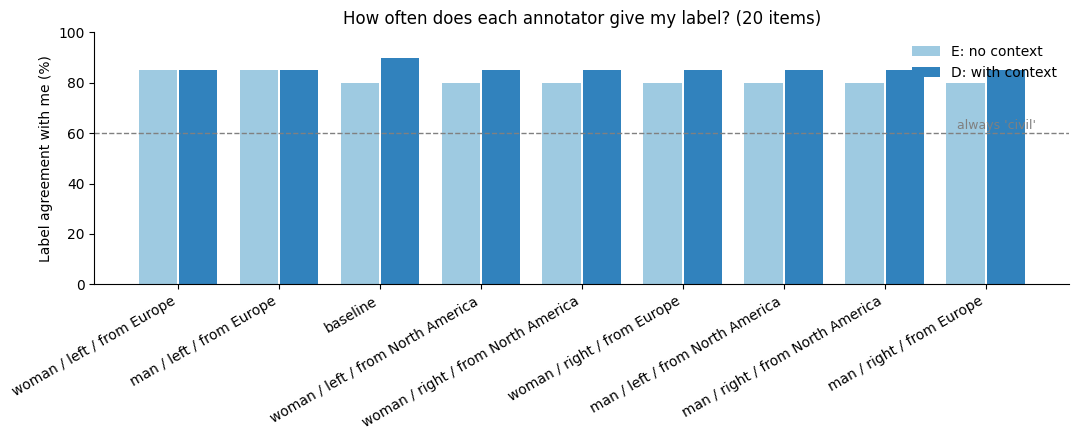

In [ ]:
# figure: label agreement with me per annotator, without and with context
order = rank_E.index
x = np.arange(len(order))
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(x - 0.2, vs_me.loc[order, "label E"] * 100, width=0.38, color="#9ecae1", label="E: no context")
ax.bar(x + 0.2, vs_me.loc[order, "label D"] * 100, width=0.38, color="#3182bd", label="D: with context")
ax.axhline((me["label"] == "civil").mean() * 100, color="grey", ls="--", lw=1)
ax.text(len(order) - 0.5, (me["label"] == "civil").mean() * 100 + 1.5, "always 'civil'", color="grey", ha="right", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(order, rotation=30, ha="right")
ax.set_ylabel("Label agreement with me (%)")
ax.set_ylim(0, 100)
ax.set_title("How often does each annotator give my label? (20 items)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


All annotators agree with me on most labels: 80-85% without context and 85-90% with context, well above the 60% that an annotator would reach by always answering "civil". The exact rating agrees much less often (30-45%): the models usually choose the same side as I do, but not the same number. They are also stricter than I am: I labelled 8 of 20 items as toxic, they labelled 10-12. The differences between the personas, and between the personas and the baseline, are at most three items. Without context the closest annotators are woman / left / from Europe and man / left / from Europe (85% label, 45% exact), one item above the rest. With context the baseline is closest (90%), and all personas reach 85%. So the closest identity changes with the context and is not a stable result. The closest persona happens to match my own profile, but this does not mean that I annotate like this identity: the difference is one item, and the man with the same attributes is equally close. With context every annotator agrees with my label as often or more often, but the left personas agree less often on the exact rating (for example 45% to 35%). So the context brings the models closer to me on the label, not on the exact rating.

### Comparison 3: how much does the context move each annotator? (E against D)

In [ ]:
rows = []
for n in names:
    e, d = ratings_of(E, n), ratings_of(D, n)
    lab_agree, exact_agree = agreement(e, d)
    diff = (d["rating"] - e["rating"]).dropna()
    rows.append({"annotator": n, "label E=D": lab_agree, "exact E=D": exact_agree,
                 "items up in D": int((diff > 0).sum()), "items down in D": int((diff < 0).sum()),
                 "mean rating E": e["rating"].mean(), "mean rating D": d["rating"].mean(),
                 "toxic E": int((e["label"] == "toxic").sum()), "toxic D": int((d["label"] == "toxic").sum())})
moved = pd.DataFrame(rows).set_index("annotator")
display(moved.style.format({"label E=D": fmt, "exact E=D": fmt, "mean rating E": "{:.2f}", "mean rating D": "{:.2f}"}))
print(f"My mean rating: {me['rating'].mean():.2f}, my toxic items: {(me['label'] == 'toxic').sum()}")

,label E=D,exact E=D,items up in D,items down in D,mean rating E,mean rating D,toxic E,toxic D
annotator,,,,,,,,
baseline,90%,60%,2,6,3.00,2.70,12,10
woman / left / from North America,85%,75%,1,4,3.10,2.85,12,11
woman / left / from Europe,90%,80%,1,3,3.05,2.90,11,11
woman / right / from North America,85%,65%,2,5,3.00,2.85,12,11
woman / right / from Europe,85%,65%,2,5,3.00,2.85,12,11
man / left / from North America,85%,75%,1,4,3.10,2.90,12,11
man / left / from Europe,90%,80%,1,3,3.05,2.90,11,11
man / right / from North America,85%,60%,2,6,3.00,2.80,12,11
man / right / from Europe,85%,65%,2,5,3.00,2.85,12,11


My mean rating: 2.35, my toxic items: 8


The context changes few labels but more ratings: for every annotator the label stays the same on 85-90% of the items, the exact rating on 60-80%. So reading the conversation mostly changes how strongly an annotator judges an item, less whether it is toxic at all. The direction is the same for all nine annotators: more items go down than up (3-6 against 1-2), and the mean rating drops by 0.15 to 0.30 points, closer to my mean of 2.35. That all annotators move the same way is a stronger sign than the size of the shift. I think it comes from part C: the participants were mostly polite and often discussed the topic instead of the insult, which may make an item look less severe. This is the opposite of what I expected, since the conversations usually condemned the toxic items. The baseline is moved the most (60% the same exact rating, 12 to 10 toxic items) and the two "left / from Europe" personas the least (80%), so a persona seems to make the model slightly more stable. Gender plays almost no role: a woman and a man with the same politics and origin always change the same labels and differ by at most one exact rating.

### Comparison 4: annotator against annotator, within each condition

Agreement of every pair (the baseline is one more annotator), as heatmaps, plus the average over all pairs per condition.

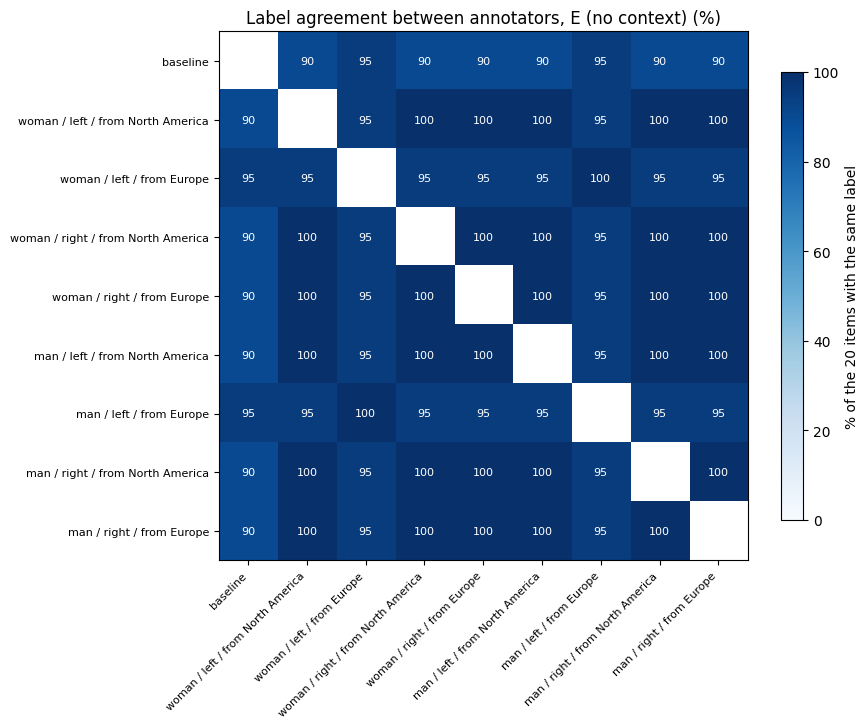

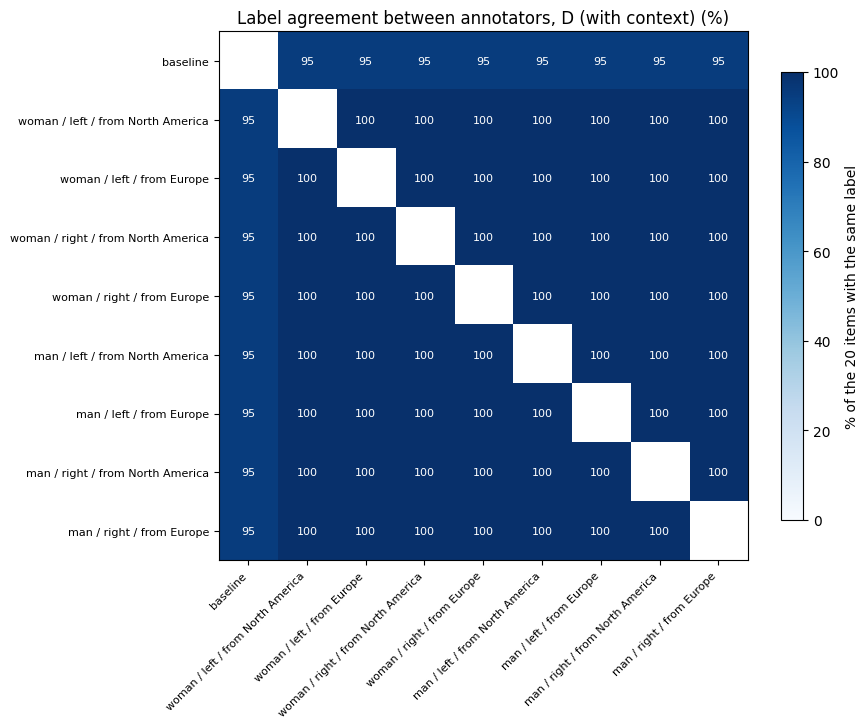

,E (no context),D (with context)
average label agreement,96%,99%
average exact agreement,91%,93%


In [ ]:
def pair_matrix(df, kind):
    k = 0 if kind == "label" else 1
    M = pd.DataFrame(index=names, columns=names, dtype=float)
    for a in names:
        for b in names:
            M.loc[a, b] = agreement(ratings_of(df, a), ratings_of(df, b))[k]
    return M

mats = {(c, k): pair_matrix(df, k) for c, df in [("E (no context)", E), ("D (with context)", D)] for k in ["label", "exact"]}

for cond in ["E (no context)", "D (with context)"]:
    M = mats[(cond, "label")].values * 100
    np.fill_diagonal(M, np.nan)                         # an annotator against itself is not a comparison
    fig, ax = plt.subplots(figsize=(9, 7.5))
    im = ax.imshow(M, cmap="Blues", vmin=0, vmax=100)
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels(names, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(names, fontsize=8)
    for i in range(len(names)):
        for j in range(len(names)):
            if i != j:
                ax.text(j, i, f"{M[i, j]:.0f}", ha="center", va="center", fontsize=8,
                        color="white" if M[i, j] > 60 else "black")
    ax.set_title(f"Label agreement between annotators, {cond} (%)")
    fig.colorbar(im, ax=ax, shrink=0.8, label="% of the 20 items with the same label")
    plt.tight_layout()
    plt.show()

pairs_idx = list(combinations(names, 2))
summary = pd.DataFrame({cond: {f"average {k} agreement": np.mean([mats[(cond, k)].loc[a, b] for a, b in pairs_idx])
                               for k in ["label", "exact"]}
                        for cond in ["E (no context)", "D (with context)"]})
display(summary.style.format(fmt))

The annotators are almost one and the same annotator. Without context two annotators agree on 96% of the labels and 91% of the exact ratings on average, with context on 99% and 93%. In D all eight personas give exactly the same labels, and only the baseline differs by one item. This is much higher than their agreement with me (80-90% label, 30-45% exact): the judgement depends on the model and the guidelines, not on the persona. Reading the same conversation pulls them even closer together, which fits with the conversation itself containing a judgement. Of the three dimensions, gender makes no difference to the labels, origin only for the left personas without context (one item), and politics at most one item. I think the main reasons are the detailed guidelines, which leave little room for interpretation, and that a short description such as "woman, left, from Europe" gives the model little to work with, but I did not test this. For the idea behind the assignment this is an important result: disagreement between annotators is information, and real people with different backgrounds would disagree more. These personas do not reproduce that disagreement but reduce it almost to zero.

## G. Conclusion

The research question was whether a model that plays a person labels like real people, and what changes when it first reads a conversation about the text. My study is small: 20 items, one model for both the conversations and the annotations (Qwen2.5-7B, chosen after comparing it with Qwen2.5-3B in part C), and a grid of eight short personas with two values per dimension plus a baseline, so my answer only holds for this setting. Within it, the annotators mostly agreed with me on the label but not on the exact rating, and the persona hardly changed their judgement. More research, with more annotators, items and models, would be needed to see whether this holds in general.


The annotators agree with my label on 80-90% of the items, but on the exact rating only on 30-45%, and they are stricter than I am (10-12 toxic items against my 8). A large part of the agreement on the label probably comes from my own guidelines: every annotator received the same instructions that I used myself, so they judged with the same definition of toxic. This makes their labels comparable to mine, but it also leaves little room for the persona. The personas agree with each other on 96-99% of the labels, much more than with me, so in practice they behave as one annotator. Gender makes no difference to the labels, and politics and origin at most one item. The closest identity (woman / left / from Europe without context, the baseline with context) is only one item ahead of the others and changes with the context, so it is not a stable result, and it does not mean that I am that identity or that my ratings reflect it.

The context moves all nine annotators in the same direction: their ratings go down, and their labels come slightly closer to mine. I think this comes from the conversations of part C, which were very de-escalating: the participants were polite, discussed the topic instead of the insult, and often ignored the stance I gave them. This was the opposite of what I expected. The context also makes the annotators even more alike (99% the same label), because they all read the same judgement. Item 19 shows that the context can also change which words an annotator sees as toxic, even when the rating stays the same.

For the idea behind the assignment this is the most important point: for subjective tasks, disagreement between annotators is information. These personas do not reproduce that disagreement but reduce it almost to zero, so I would not use them to replace a group of real annotators.

### Limitations

The results are based on 20 items, so one item is 5 percentage points and most differences between personas are within the noise. I used one model (Qwen2.5-7B, 4-bit), with greedy decoding and one run, so I do not know how stable the differences are. Every item has only one generated conversation, made by the same model that annotated, and these conversations are not neutral: they are a bias in themselves. The personas are only short descriptions of three attributes. My own ratings are a reference point, not the truth: a low agreement means "different from me", not "wrong". Finally, the format examples in the instructions share a word with items 1 and 16, and the apostrophes in item 19 caused 9 invalid evidence answers.

### Further research

Several things could be explored further. First, an analysis per item: on which items do the annotators differ from me, and from each other, and why. Second, other models: I wanted to test Llama-3.1-8B, but did not have enough time and GPU access. Third, the conversations: the stances of the participants hardly came through, and all conversations were de-escalating. It would be interesting to generate heated discussions as well, and see whether they push the ratings up. Fourth, the annotator personas could be more complex, with more and more varied attributes. Now they might be too similar to each other to show real differences. Running the same annotators without my guidelines would also show how much the guidelines, and not the personas, decide the labels.

### AI use and sources

I used Claude (Anthropic) for explanations of SynDisco, for code suggestions, and to check my texts against my own results. The full record of that conversation is in `llm_interactions.md`. For the code I also used other language models in separate chats, mainly to get parts of the code working. For the writing I sometimes used AI to turn my notes into a coherent story. These are not summarised in the same file because I asked my main chat to make the `llm_interactions.md` file.

Sources: the assignment text and the lab notebook of the course, the SynDisco documentation (overview, discussion guide and annotation guide) and the SynDisco paper, the model card of Qwen2.5-7B-Instruct (unsloth/Qwen2.5-7B-Instruct-bnb-4bit) on Hugging Face, the pandas and matplotlib documentation.